# Source estimation


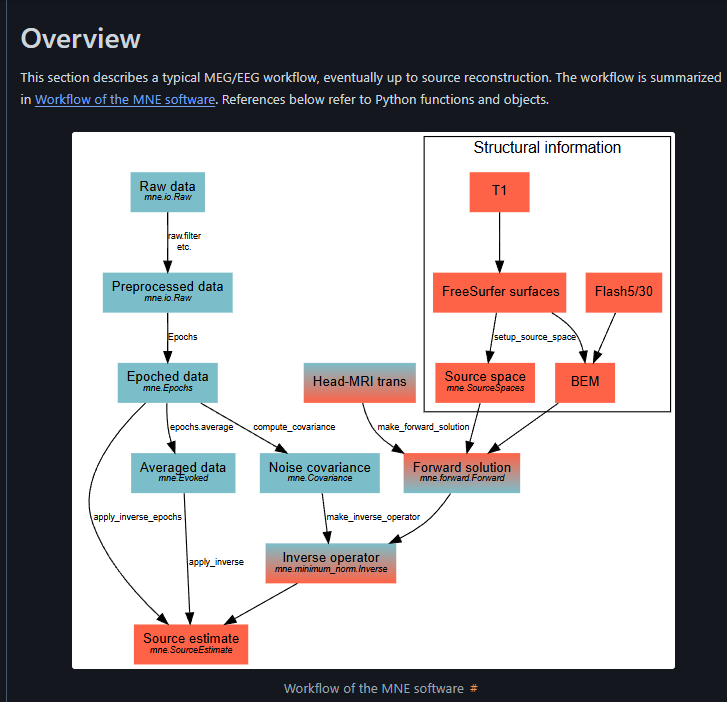

**Structural info means Mri scan**

In [1]:
import pathlib
import matplotlib
import matplotlib.pyplot as plt
import mne_bids
import mne

matplotlib.use('QtAgg')
mne.set_log_level('warning')

## Start with some fresh epochs

In [ ]:
bids_root = pathlib.Path('out_data/sample_BIDS')

bids_path = mne_bids.BIDSPath(subject='01',
                              session='01',
                              task='audiovisual',
                              run='01',
                              datatype='meg',
                              root=bids_root)

raw = mne_bids.read_raw_bids(bids_path)
raw.load_data()
raw.filter(l_freq=0.1, h_freq=40)
events, event_id = mne.events_from_annotations(raw)

tmin = -0.200
tmax = 0.500
baseline = (None, 0)

epochs = mne.Epochs(raw,
                    events=events,
                    event_id=event_id,
                    tmin=tmin,
                    tmax=tmax,
                    baseline=baseline,
                    preload=True,
                    proj=False)
epochs.save(pathlib.Path('out_data') / 'epochs_for_source_epo.fif', overwrite=True)

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 0
 proj_name: mne_anonymize
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
 subject_info: <subject_info | his_id: sub-01, birthday: 1988-12-02, sex: 1, hand: 3>
>

In [3]:
print(epochs.info)

<Info | 22 non-empty values
 acq_pars: ACQch001 110113 ACQch002 110112 ACQch003 110111 ACQch004 110122 ...
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 description: Anonymized using a time shift to preserve age at acquisition
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 events: 1 item (list)
 experimenter: mne_anonymize
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_results: 1 item (list)
 line_freq: 60.0
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 proj_id: 0
 proj_name: mne_anonymize
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off
 sfreq: 600.6 Hz
 subject_info: <subject_info | his_id: sub-01, birthday: 1988-12-02, sex: 1, hand: 3>
>


## View the BEM (Boundery element model)

## Normally you make your oun bem firs 
in t1 mri via `mne.bem.make_watershed_bem()` or `mne.bem.make_flash_bem` check the documentaiotn for new methods

In [5]:
subjects_dir = pathlib.Path(mne.datasets.sample.data_path()) / 'subjects'

mne.viz.plot_bem(subject='sample', subjects_dir=subjects_dir,
                 orientation='coronal')

<MNEFigure size 975x913.75 with 12 Axes>

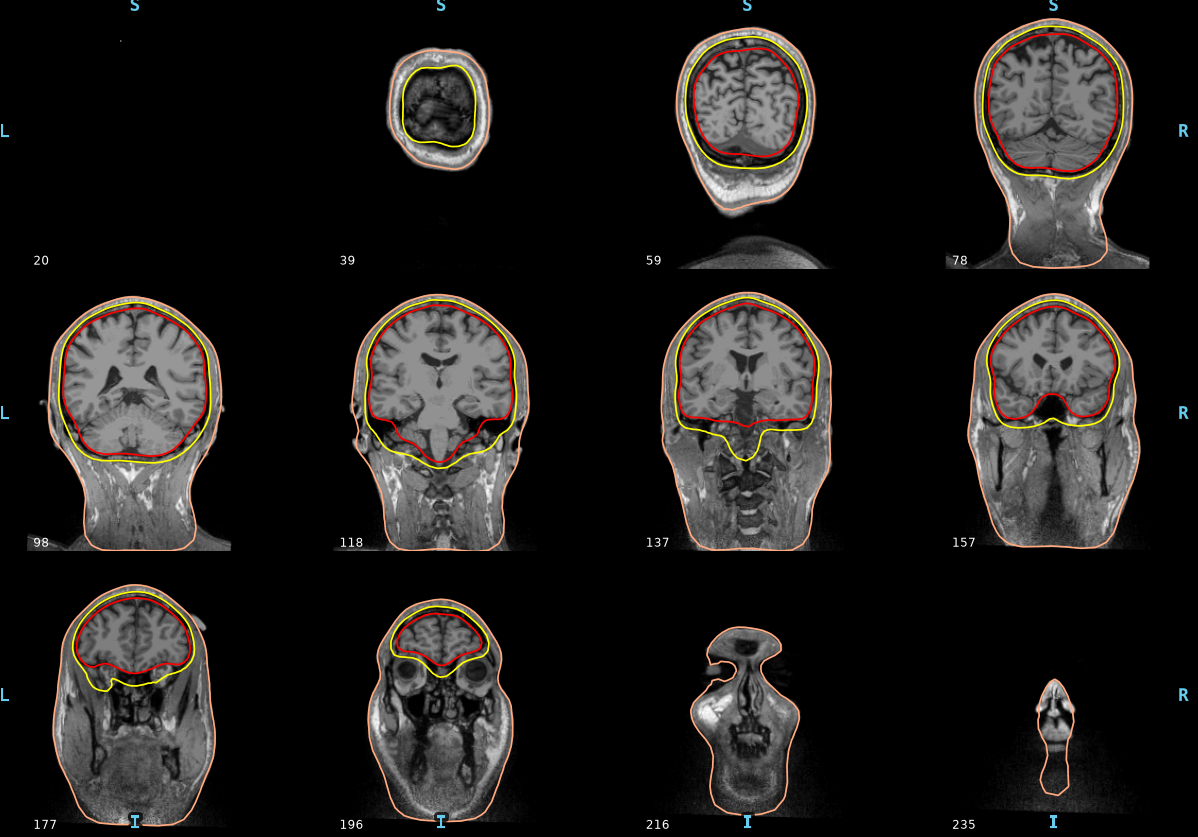

**BEM — Boundary Element Model**

A BEM is a **model of the head** used to help estimate where EEG/MEG signals come from inside the brain.

**1. Why do we need it?**

The signals measured by sensors depend on the source location, head shape, tissue conductivity, and sensor positions.

| Process | Question |
|---|---|
| **Forward modeling** | If a source is active here in the brain, what will the sensors measure? |
| **Inverse modeling** | Given the signals measured by sensors, where might the sources be? |

The **BEM helps calculate the forward model**. We then use the forward model to estimate brain sources.

**2. What does the image show?**

The gray background is a **T1 structural MRI**, which shows the anatomy of the head.

Each small image is a different **slice of the same person’s head**, not a different time point.

The colored lines show three surfaces:

| Color | Surface | Meaning |
|---|---|---|
| Red | Inner skull | Inner boundary of the skull |
| Yellow | Outer skull | Outer boundary of the skull |
| Orange | Scalp | Outer surface of the head |

**Correction to the transcript:** These lines do **not** represent gray matter and white matter. They represent the skull and scalp boundaries.

The numbers are **slice numbers**. The letters indicate directions: **S = top**, **I = bottom**, and **R = the person’s right**.

**3. Where does this BEM come from?**

The MNE sample dataset already includes prepared BEM surfaces for the sample subject.

These surfaces are prepared from MRI data using tools such as **FreeSurfer and MNE**. Preparing them can take time, so the workshop uses the existing surfaces.

*BEM surfaces* and *brain parcellation* are different:

- **BEM surfaces:** boundaries used to model the head.
- **Brain parcellation:** dividing the brain into named regions.

**4. What does the code do?**

```python
# Find the folder containing the sample subject's anatomy
subjects_dir = pathlib.Path(
    mne.datasets.sample.data_path()
) / 'subjects'

# Show the existing BEM surfaces on the MRI
mne.viz.plot_bem(
    subject='sample',
    subjects_dir=subjects_dir,
    orientation='coronal'
)
```

- `subject='sample'`: use the sample subject’s anatomy.
- `subjects_dir`: location of the anatomical files.
- `orientation='coronal'`: show slices as if looking at the person from the front.
- `plot_bem()`: display the MRI and existing surfaces.

**This code displays the BEM surfaces. It does not create them from EEG signals or calculate brain activity.**

**5. Why do we check this plot?**

We check that the surfaces follow the head anatomy correctly:

- The scalp surface follows the outside of the head.
- The skull surfaces follow the skull.
- The surfaces do not cross each other.

This is a **quality check** before source estimation.

**6. Is the printed `Info` the BEM?**

No. They describe different things:

| Item | What it describes |
|---|---|
| `Info` | Recording details: channels, sampling rate, bad channels, and sensor information |
| BEM | Head geometry and tissue boundaries used for modeling |

Source estimation also needs possible source locations and alignment between the sensors and MRI.

**7. Note about projectors**

**SSP projectors** remove certain unwanted signal patterns, such as noise.

```text
PCA-v1: off, PCA-v2: off, PCA-v3: off
```

This means the projectors are stored in the object, but have not been applied to its data.

MNE automatically handles projection during `apply_inverse()`.

**Correction to the transcript:** Applying projectors before inverse modeling is not automatically an error. MNE can work with already-applied projectors; the projector settings must be consistent between the data and inverse model.

## Coregistration!

`mne` need to know where the sensors and where located on your participant's head
(positioning thes sensors on head the head) this process called coregistration


In [8]:
epochs_fname = pathlib.Path('out_data') / 'epochs_for_source_epo.fif'

# Interactive GUI (optional): fit the head to the MRI, then click "Save" and
# store the file as out_data/sample-trans.fif (MNE expects names ending in -trans.fif)
mne.gui.coregistration(
    subject='sample',
    subjects_dir=subjects_dir,
    inst=epochs_fname,
    scale_by_distance=False,
    orient_to_surface=False
)

In [21]:
# Use your own coregistration if you saved one, otherwise fall back to the
# ready-made transform that ships with the MNE sample dataset (same recording)
trans_fname = pathlib.Path('out_data') / 'sample-trans.fif'
epochs_fname = pathlib.Path('out_data') / 'epochs_for_source_epo.fif'
 
info = mne.io.read_info(epochs_fname)

mne.viz.set_3d_backend('pyvista')

fig = mne.viz.plot_alignment(
    info=info,trans=trans_fname,
    subject='sample',
    subjects_dir=subjects_dir,
    dig=True,
    surfaces='head-dense',
    verbose = True
)

Using lh.seghead for head surface.
Getting helmet for system 306m
Channel types::	grad: 203, mag: 102, eeg: 59


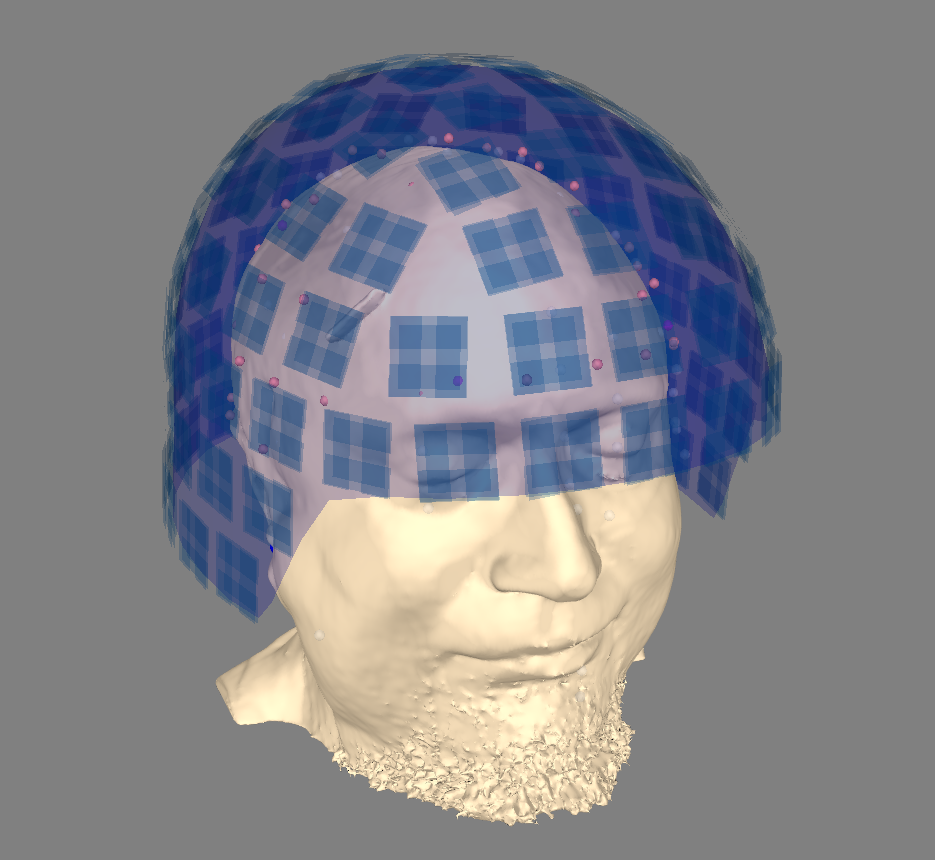

# We have done with HEAD_MRI_TRANS

## Compute the Source Space

The **source space** defines the possible locations of brain activity that we will estimate later.

This step selects candidate points on the cortical surface in both brain hemispheres. **It does not calculate activity or identify active areas yet.**

```python
subject = 'sample'

src = mne.setup_source_space(
    subject=subject,             # Subject whose anatomy we use
    spacing='oct4',              # Small source grid for a fast demonstration
    subjects_dir=subjects_dir,  # Folder containing the anatomical files
    add_dist=False              # Skip extra surface-distance calculations
)

src  # Show a summary
```

| Parameter | Meaning |
|---|---|
| `subject` | Selects the subject’s brain anatomy. |
| `spacing` | Controls how densely the candidate source points are placed. |
| `subjects_dir` | Location of the subjects’ anatomical files. |
| `add_dist` | Controls extra distance calculations along the brain surface. |

**`oct4` vs. `oct6`**

| Setting | Points per hemisphere | Total points |
|---|---:|---:|
| `oct4` | 258 | 516 |
| `oct6` | 4,098 | 8,196 |

- `oct4` is fast and useful for learning.
- `oct6` provides a denser grid and is commonly used for actual analysis.
- The number in `oct4` is a subdivision level, **not a distance in millimeters**.
- More points increase computation; they do not automatically guarantee more accurate localization.

**What does `add_dist=False` mean?**

It skips extra calculations of distances along the cortical surface to save time. It does **not** change the selected source locations.

Removing this argument uses the default `add_dist=True`. However, these extra calculations are not required for every analysis.

**What is stored in `src`?**

It contains the geometry of the candidate sources, including their locations and surface orientations:

```python
src[0]  # Left hemisphere
src[1]  # Right hemisphere
```

The next **forward-modeling** step uses these locations to predict what the sensors would measure if a source were active at each location.

In [23]:
subject = 'sample'
src = mne.setup_source_space(subject=subject,
                             spacing='oct6',  # Use oct6 during an actual analysis!
                             subjects_dir=subjects_dir,
                             add_dist=False)  # Remove this one during an actual analysis!
src

<SourceSpaces: [<surface (lh), n_vertices=155407, n_used=4098>, <surface (rh), n_vertices=156866, n_used=4098>] MRI (surface RAS) coords, subject 'sample', ~24.1 MiB>

In [24]:
mne.viz.plot_alignment(info=info, trans=trans_fname, subject=subject,
                       src=src, subjects_dir=subjects_dir, dig=True,
                       surfaces= ['head-dense', 'white'], coord_frame='meg')

## **oct4**
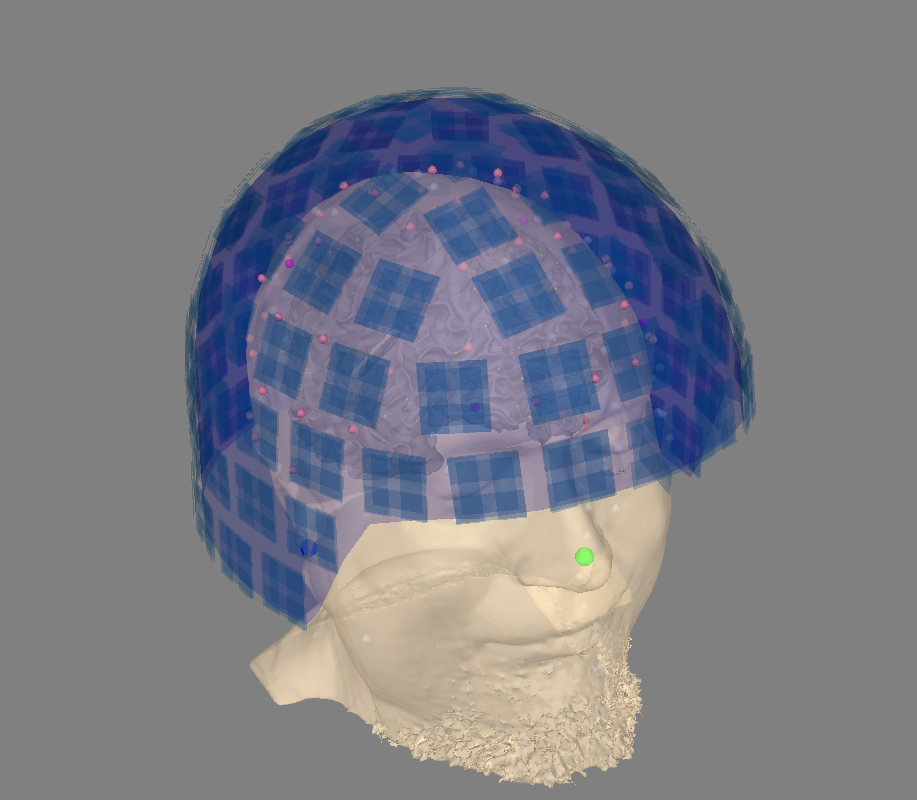

## **oct6**

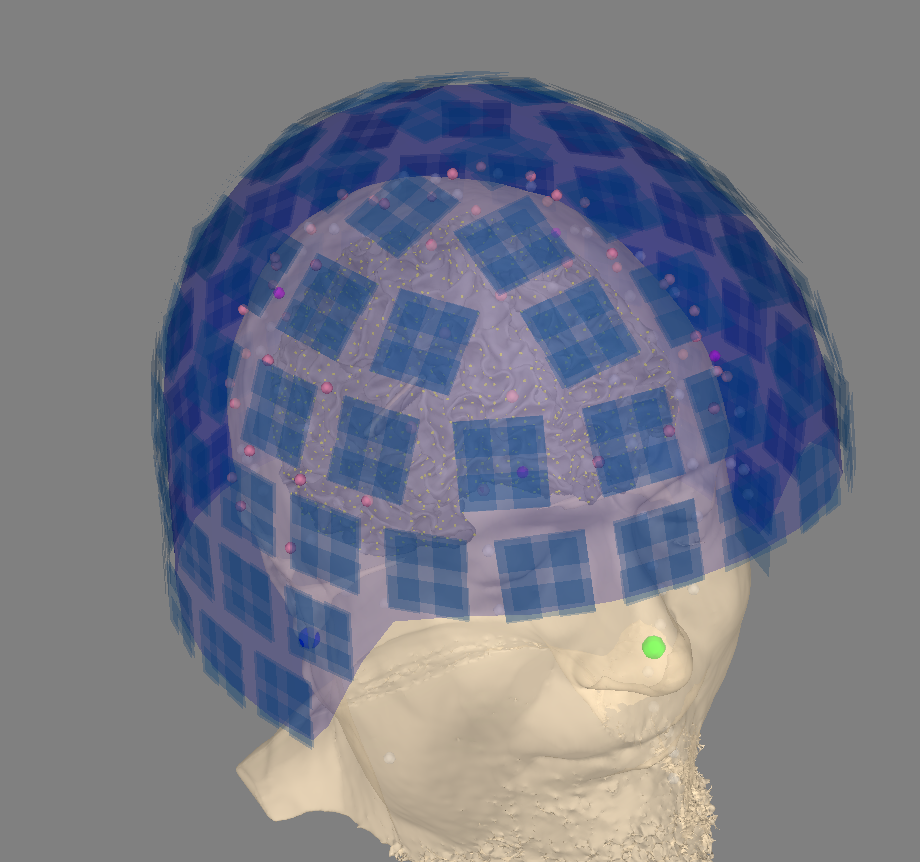

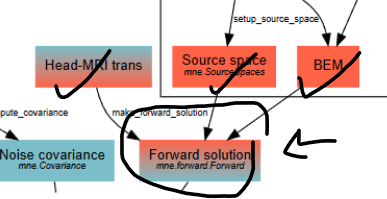

## Compute the Forward Solution

The **forward solution** predicts what the EEG/MEG sensors would measure if a source at a particular brain location were active.

It answers:

> **“If a source is active here, what signal will each sensor detect?”**

To calculate it, we combine:

| Input | Purpose |
|---|---|
| **Source space (`src`)** | Candidate source locations in the brain |
| **BEM solution (`bem`)** | Models how the head’s tissues affect the measurements |
| **Transformation (`trans`)** | Aligns the head and sensors with the MRI |
| **Recording information (`info`)** | Provides sensor positions, orientations, and types |

The result includes a **lead-field matrix**, which maps source activity to predicted sensor signals.

**Example:** A source at location A produces one pattern across the sensors. A source at location B produces a different pattern. The forward solution calculates these patterns.

**This step does not identify the actual active sources.** Later, the **inverse solution** uses the forward model and recorded EEG/MEG signals to estimate source activity.

In [25]:
conductivity = (0.3,)  # for single layer – used in MEG
# conductivity = (0.3, 0.006, 0.3)  # for three layers – used in EEG
model = mne.make_bem_model(subject=subject, ico=4,
                           conductivity=conductivity,
                           subjects_dir=subjects_dir)
model

[{'id': 1 (FIFFV_BEM_SURF_ID_BRAIN),
  'sigma': np.float64(0.3),
  'np': 2562,
  'ntri': 5120,
  'coord_frame': 5,
  'rr': array([[ 0.0006128, -0.007984 ,  0.103732 ],
         [ 0.0568749, -0.0089022,  0.073789 ],
         [ 0.0235464,  0.0574384,  0.0829638],
         ...,
         [ 0.007272 ,  0.0033751, -0.0268523],
         [ 0.0017443,  0.0061639, -0.0268488],
         [ 0.0038775,  0.003904 , -0.0327116]], shape=(2562, 3)),
  'nn': array([[-1.41976393e-05,  1.38905590e-18,  1.00000000e+00],
         [ 8.94547443e-01,  0.00000000e+00,  4.46973010e-01],
         [ 2.76442723e-01,  8.50701266e-01,  4.47086991e-01],
         ...,
         [ 9.06305003e-02,  1.47212416e-01, -9.84943966e-01],
         [ 1.32152692e-02,  1.72348009e-01, -9.84947471e-01],
         [ 3.46996163e-02,  1.06791635e-01, -9.93675744e-01]],
        shape=(2562, 3)),
  'tris': array([[   0,  644,  642],
         [ 642,  643,  162],
         [ 644,  643,  642],
         ...,
         [2561, 2201,  557],
       

In [26]:
bem_sol = mne.make_bem_solution(model)
bem_sol

<ConductorModel | BEM (1 layer) solver=mne>

In [27]:
bem_fname = pathlib.Path('out_data') / 'sample-bem-sol.fif'
mne.bem.write_bem_solution(bem_fname, bem_sol, overwrite=True)

In [28]:
fwd = mne.make_forward_solution(info,
                                trans=trans_fname,
                                src=src,
                                bem=bem_sol,
                                meg=True, # include MEG channels
                                eeg=False, # exclude EEG channels
                                mindist=5.0, # ignore sources <= 5mm from inner skull
                                n_jobs=1) # number of jobs to run in parallel
fwd

<Forward | MEG channels: 306 | EEG channels: 0 | Source space: Surface with 7498 vertices | Source orientation: Free>

In [29]:
fwd_fname = pathlib.Path('out_data') / 'sample_fwd.fif'
mne.write_forward_solution(fwd_fname, fwd, overwrite=True)

## Compute noise covariance

In [30]:
noise_cov = mne.compute_covariance(epochs, tmax=0.,
                                   method=['shrunk', 'empirical'],
                                   rank='info')
mne.viz.plot_cov(noise_cov, info=epochs.info)

C:\Program Files\Python313\Lib\contextlib.py:85: RuntimeWarning: No average EEG reference present in info["projs"], covariance may be adversely affected. Consider recomputing covariance using with an average eeg reference projector added.
  return func(*args, **kwds)


(<Figure size 1425x462.5 with 6 Axes>, <Figure size 1425x462.5 with 3 Axes>)

In [31]:
# average the epochs of one condition and check the whitening
evoked = epochs['Auditory/Left'].average()
evoked.plot_white(noise_cov)

C:\Users\Zakaria\AppData\Local\Temp\ipykernel_8804\2174323007.py:3: RuntimeWarning: No average EEG reference present in info["projs"], covariance may be adversely affected. Consider recomputing covariance using with an average eeg reference projector added.
  evoked.plot_white(noise_cov)


<Figure size 1100x1010 with 7 Axes>

## Create the inverse operator

In [32]:
from mne.minimum_norm import (make_inverse_operator, apply_inverse,
                              write_inverse_operator)

In [33]:
# fwd was computed above (MEG only, eeg=False); re-load it from disk if needed:
# fwd = mne.read_forward_solution(fwd_fname)
fwd = mne.convert_forward_solution(fwd, surf_ori=True)

inverse_operator = make_inverse_operator(evoked.info, fwd, noise_cov,
                                         loose=0.2, depth=0.8)
write_inverse_operator(pathlib.Path('out_data') / 'sample-inv.fif',
                       inverse_operator, overwrite=True)

## Apply the inverse operator -> Calculate the source estimate

In [34]:
method = "dSPM"
snr = 3.
lambda2 = 1. / snr ** 2
stc = apply_inverse(evoked, inverse_operator, lambda2,
                    method=method, pick_ori=None)
stc

<SourceEstimate | 7498 vertices, subject : sample, tmin : -199.79521315838787 (ms), tmax : 499.48803289596964 (ms), tstep : 1.6649601096532323 (ms), data shape : (7498, 421), ~24.1 MiB>

## Show the result!

In [36]:
brain = stc.plot(surface='inflated',
                 hemi='both',
                 subjects_dir=subjects_dir,
                 time_viewer=True)